# Capitolo 9 — Convoluzioni e normalizzazione
 **Arcangelo Distante e Cosimo Distante**

 Questo laboratorio verifica metodi con array analitici o dati sintetici. Non usa immagini esterne, pesi preaddestrati o download di dataset. Le attività aperte **N9.A1–N9.A3** chiedono di distinguere ciò che il calcolo dimostra dai limiti dell’esempio.

 ## Avvio e salvataggio
 In Google Colab, aprire il notebook dal repository GitHub attraverso **File → Apri notebook → GitHub**, oppure caricare questo file. Scegliere un runtime CPU: NumPy e Matplotlib sono sufficienti. Eseguire le celle dall’alto verso il basso; per ripartire, riavviare il runtime e rieseguire tutto. In locale usare Jupyter con Python 3, NumPy e Matplotlib. Nessun altro materiale deve essere caricato.

 I risultati sono salvati in `output_capitolo09` nella cartella di lavoro. Al termine scaricare la cartella degli output e salvare una copia del notebook eseguito. In Colab i file del runtime sono temporanei. Un’esecuzione locale non documenta automaticamente una prova svolta nel servizio Colab.


In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
OUTPUT = Path("output_capitolo09")
OUTPUT.mkdir(exist_ok=True)
risultati = {"capitolo": 9, "natura": "esempi analitici e sintetici", "dispositivo": "CPU"}
def mostra(a):
    return np.array2string(np.asarray(a), precision=6, separator=", ")


## N9.A1 — Il gradiente di un kernel condiviso
Usiamo la cross-correlazione valida dell’esempio analitico e una loss quadratica con target zero. **Domande:** perché il kernel non viene ribaltato? Da quali posizioni arriva il gradiente del suo primo coefficiente? Aumentare l’area dell’input cambia il numero di coefficienti appresi?


In [2]:
X=np.array([[1.,2.,0.],[0.,1.,3.],[2.,0.,1.]])
K=np.array([[1.,-1.],[0.,2.]])
def corr(X,K):
    h,w=X.shape;kh,kw=K.shape
    return np.array([[np.sum(X[i:i+kh,j:j+kw]*K) for j in range(w-kw+1)] for i in range(h-kh+1)])
Y=corr(X,K);L=.5*np.sum(Y**2);dK=np.zeros_like(K)
for i,j in np.ndindex(Y.shape):dK+=Y[i,j]*X[i:i+2,j:j+2]
eps=1e-5;fd=np.zeros_like(K)
for ix in np.ndindex(K.shape):
    kp=K.copy();km=K.copy();kp[ix]+=eps;km[ix]-=eps
    fd[ix]=(.5*np.sum(corr(X,kp)**2)-.5*np.sum(corr(X,km)**2))/(2*eps)
print("Y:",mostra(Y),"Loss:",L,"Gradiente:",mostra(dK),sep="\n")
assert np.allclose(dK,fd,atol=1e-7)
risultati["convoluzione"]={"output":Y.tolist(),"loss":float(L),"gradiente_kernel":dK.tolist(),"errore_fd":float(np.max(abs(dK-fd)))}


Y:
[[ 1.,  8.],
 [-1.,  0.]]
Loss:
33.0
Gradiente:
[[17.,  1.],
 [ 6., 25.]]


## N9.A2 — Forma e campo recettivo
La catena Conv3, Pool2, Conv3, Pool2 è un calcolo geometrico, non una CNN addestrata. **Domande:** perché un elemento finale ha un campo recettivo maggiore dell’immagine 8×8? Il supporto nominale prova che ogni pixel ha influenza non nulla? Quanti coefficienti ha un kernel 3×3 con dilation 2 e qual è il suo ingombro?


In [3]:
r,j,size=1,1,8;rows=[]
for name,k,s,p in [("Conv1",3,1,1),("Pool1",2,2,0),("Conv2",3,1,1),("Pool2",2,2,0)]:
    size=(size+2*p-(k-1)-1)//s+1
    r=r+(k-1)*j;j*=s;rows.append([name,size,r,j])
print("Layer, lato output, campo recettivo, salto")
for row in rows:print(row)
assert (size,r,j)==(2,10,4)
risultati["geometria"]={"layer":rows,"dilation_2":{"coefficienti_spaziali":9,"ingombro":5}}
with (OUTPUT/"campo_recettivo.csv").open("w") as f:
    f.write("layer,lato_output,campo_recettivo,salto\n")
    for row in rows:f.write(",".join(map(str,row))+"\n")


Layer, lato output, campo recettivo, salto
['Conv1', 8, 3, 1]
['Pool1', 4, 4, 2]
['Conv2', 4, 8, 2]
['Pool2', 2, 10, 4]


## N9.A3 — BatchNorm: output e stato
Riproduciamo analiticamente la convenzione di un canale con quattro valori, gamma 1, beta 0 e aggiornamento dei buffer di peso 0.1. Il forward di training usa la varianza con divisore m; l’aggiornamento della running variance usa il correttivo m/(m−1). **Domande:** che cosa cambia fra train ed eval dopo un solo batch? Perché non registrare gradienti non equivale a fissare i buffer? Quali valori condividono le statistiche in GroupNorm e in LayerNorm(C,H,W)?


Train:
[-1.341639, -0.447213,  0.447213,  1.341639]
Eval:
[0.47936 , 2.077226, 3.675091, 5.272957]
buffer:
0.4
1.5666666666666667
Gradiente input, upstream tutti uno: [0., 0., 0., 0.]


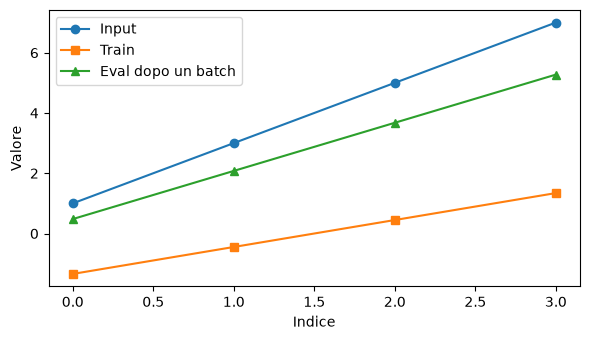

In [4]:
x=np.array([1.,3.,5.,7.]);eps=1e-5;m=x.size
mean=float(x.mean());var=float(x.var(ddof=0));train=(x-mean)/np.sqrt(var+eps)
running_mean=.9*0+.1*mean;running_var=.9*1+.1*(m/(m-1))*var
evaluation=(x-running_mean)/np.sqrt(running_var+eps)
g=np.ones_like(x);gx=(g-g.mean()-train*np.mean(g*train))/np.sqrt(var+eps)
print("Train:",mostra(train),"Eval:",mostra(evaluation),"buffer:",running_mean,running_var,sep="\n")
print("Gradiente input, upstream tutti uno:",mostra(gx))
fig,ax=plt.subplots(figsize=(6,3.5));ax.plot(x,"o-",label="Input");ax.plot(train,"s-",label="Train");ax.plot(evaluation,"^-",label="Eval dopo un batch");ax.legend();ax.set(xlabel="Indice",ylabel="Valore");fig.tight_layout();fig.savefig(OUTPUT/"batchnorm.png",dpi=160);plt.show()
risultati["batchnorm"]={"media":mean,"varianza_forward":var,"running_mean":running_mean,"running_var":running_var,"train":train.tolist(),"eval":evaluation.tolist(),"gradiente_input_upstream_uno":gx.tolist()}
assert np.allclose([mean,var,running_mean,running_var],[4,5,.4,1.5666666666666667])


In [5]:
with (OUTPUT / "risultati_capitolo09.json").open("w", encoding="utf-8") as f:
    json.dump(risultati, f, indent=2, ensure_ascii=False, allow_nan=False)
print("Risultati salvati in", OUTPUT)


Risultati salvati in output_capitolo09
